# Yapay Sinir Ağlarıyla Ötegezegen Tespiti

**Batın Dikilitaş · 240121001**
Yapay Sinir Ağları dersi projesi

Bu notebook'ta sunumda anlattığım sistemi baştan sona çalıştırıyorum:

1. **Gerçek ışık eğrisi:** NASA'nın Kepler arşivinden Kepler-90 yıldızının verisini indirip ön işleme adımlarını uyguluyorum (trend temizleme, BLS, katlama).
2. **Gerçek eğitim verisi:** Kepler ekibinin etiketlediği sinyallerin hazır işlenmiş hali (Shallue ve Vanderburg, 2018). Her sinyal için genel görünüm, yerel görünüm ve bir etiket var.
3. **1D CNN:** Genel ve yerel görünümü ayrı kolonlardan geçiren ağı kurup eğitiyorum.
4. **Değerlendirme:** Ağın hiç görmediği test setinde kesinlik, duyarlılık, F1 ve ROC eğrisi.
5. **Kepler-90:** Eğittiğim ağı Kepler-90'ın gerçek ışık eğrisinde deniyorum.

**Çalıştırmak için:** Proje klasöründe `pip install -r requirements.txt`, sonra bu notebook'ta *Run All*.
İlk çalıştırmada veri indiriliyor (yaklaşık 145 MB + Kepler-90 için birkaç MB). Sonraki çalıştırmalarda her şey
`kepler_veri` klasöründen okunuyor, yani sunum sırasında internet gerekmiyor.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import glob
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # TensorFlow'un uzun log mesajlarını gizle

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from astropy.timeseries import BoxLeastSquares
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

np.random.seed(42)
tf.random.set_seed(42)
plt.rcParams["figure.dpi"] = 110

GENEL_BIN = 2001   # genel görünümdeki nokta sayısı (tüm periyot)
YEREL_BIN = 201    # yerel görünümdeki nokta sayısı (transit çevresi)
YEREL_SURE = 4     # yerel görünüm transitin ±4 süre çevresini gösteriyor

VERI_KLASORU = "kepler_veri"
SONUC_KLASORU = "sonuclar"
os.makedirs(VERI_KLASORU, exist_ok=True)
os.makedirs(SONUC_KLASORU, exist_ok=True)

# False: sonuclar/model.keras varsa kayıtlı model yükleniyor (sunumda hızlı ve sonuçlar hep aynı).
# True: ağ baştan eğitiliyor (bu bilgisayarda yaklaşık 2 dakika).
YENIDEN_EGIT = False


def kaydet(ad):
    # Grafiği sonuclar klasörüne de kaydediyorum, sunuma koymak için
    plt.savefig(os.path.join(SONUC_KLASORU, ad + ".png"), dpi=160, bbox_inches="tight")


print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Gerçek ışık eğrisi: Kepler-90

`lightkurve` kütüphanesi NASA'nın MAST arşivine bağlanıp Kepler'in ölçümlerini indiriyor.
Kepler-90 (KIC 11442793) için yaklaşık 4 yıllık veri var. İlk seferde indirdikten sonra
`kepler_veri/kepler90.npz` dosyasına kaydediyorum, sonraki çalıştırmalarda internete gerek kalmıyor.

Kepler-90 kayıtlı dosyadan okundu.
51503 ölçüm, 1459 günlük veri


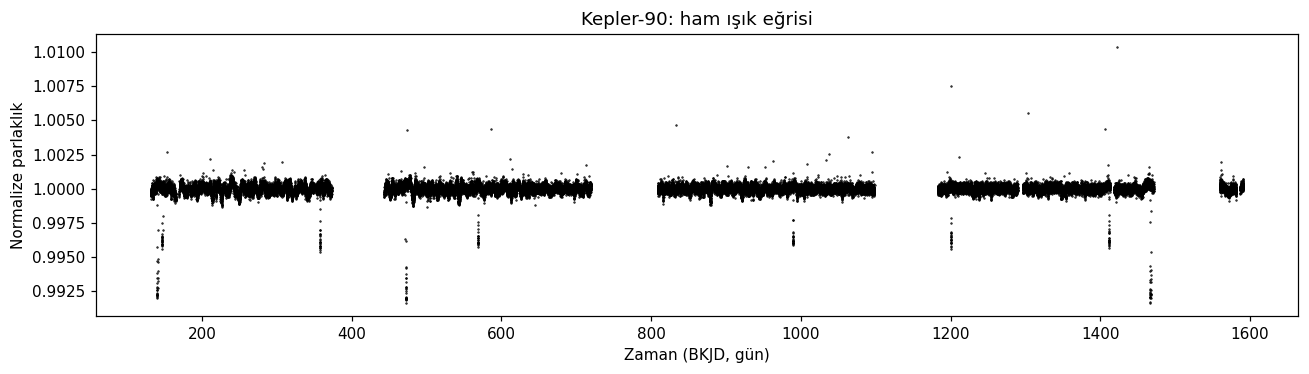

In [2]:
KEPLER90_DOSYA = os.path.join(VERI_KLASORU, "kepler90.npz")


def diziye(x):
    # lightkurve'ün döndürdüğü değerleri düz numpy dizisine çeviriyor
    if hasattr(x, "filled"):
        try:
            x = x.filled(np.nan)
        except Exception:
            pass
    if hasattr(x, "value"):
        x = x.value
    return np.asarray(x, dtype=float)


if os.path.exists(KEPLER90_DOSYA):
    d = np.load(KEPLER90_DOSYA)
    t_ham, f_ham = d["t"], d["f"]
    print("Kepler-90 kayıtlı dosyadan okundu.")
else:
    import lightkurve as lk
    arama = lk.search_lightcurve("KIC 11442793", mission="Kepler", author="Kepler", cadence="long")
    print(f"{len(arama)} çeyreklik dosya bulundu, indiriliyor...")
    lc = arama.download_all().stitch().remove_nans()
    t_ham, f_ham = diziye(lc.time), diziye(lc.flux)
    np.savez(KEPLER90_DOSYA, t=t_ham, f=f_ham)
    print("İndirildi ve kaydedildi.")

print(f"{t_ham.size} ölçüm, {t_ham.max() - t_ham.min():.0f} günlük veri")

plt.figure(figsize=(12, 3.5))
plt.plot(t_ham, f_ham, ".", ms=1, color="k")
plt.xlabel("Zaman (BKJD, gün)")
plt.ylabel("Normalize parlaklık")
plt.title("Kepler-90: ham ışık eğrisi")
plt.tight_layout()
kaydet("1_ham_isik_egrisi")
plt.show()

### 1.1 Trend temizleme
Yıldızın kendi yavaş parlaklık değişimlerini ve cihaz kaymalarını çıkarmak için kayan bir medyan filtresi kullanıyorum.
Pencereyi uzun tuttum (yaklaşık 2 gün) ki 10-15 saat süren transitler silinmesin.
Ölçümler arasında büyük boşluk olan yerlerde (çeyrek değişimleri) her parçayı ayrı ayrı temizliyorum.
Yukarı doğru sıçramaları da atıyorum; aşağı doğru olanlara dokunmuyorum çünkü transit olabilirler.

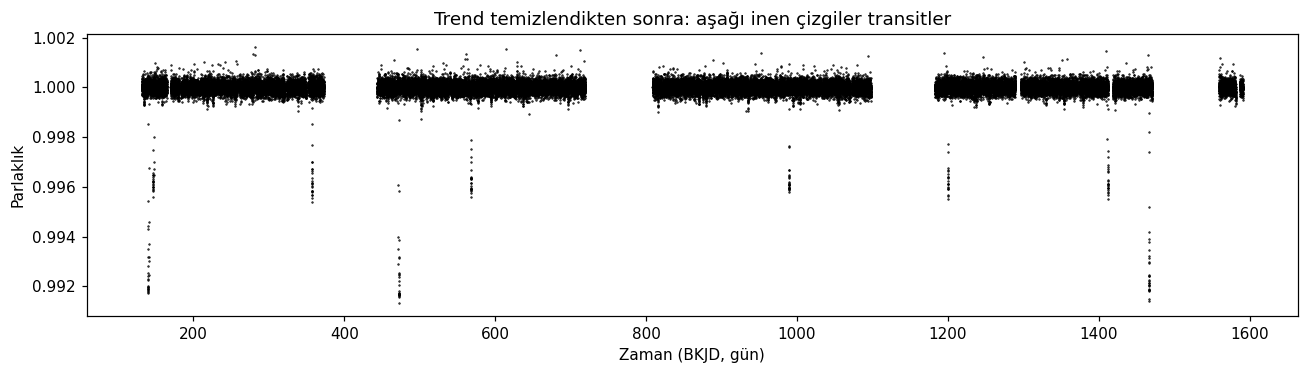

In [3]:
from scipy.ndimage import median_filter


def trend_temizle(t, f, pencere_gun=2.0):
    adim = np.median(np.diff(t))
    pencere = int(pencere_gun / adim) | 1              # tek sayı olsun
    kopuk = np.flatnonzero(np.diff(t) > 0.5) + 1        # yarım günden uzun boşluklar
    sonuc = np.empty_like(f)
    for parca in np.split(np.arange(t.size), kopuk):
        trend = median_filter(f[parca], size=min(pencere, parca.size | 1), mode="nearest")
        sonuc[parca] = f[parca] / trend
    return sonuc


iyi = np.isfinite(t_ham) & np.isfinite(f_ham)
t, f = t_ham[iyi], trend_temizle(t_ham[iyi], f_ham[iyi])
iyi = f < np.median(f) + 4 * np.std(f)
t, f = t[iyi], f[iyi]

plt.figure(figsize=(12, 3.5))
plt.plot(t, f, ".", ms=1, color="k")
plt.xlabel("Zaman (BKJD, gün)")
plt.ylabel("Parlaklık")
plt.title("Trend temizlendikten sonra: aşağı inen çizgiler transitler")
plt.tight_layout()
kaydet("2_trend_temizlenmis")
plt.show()

### 1.2 BLS ile periyot bulma
Box Least Squares (BLS) algoritması eğride kutu şeklinde tekrar eden düşüşleri arıyor.
Kepler-90'ın büyük gezegenleri uzun periyotlu olduğu için 50-400 gün arasına bakıyorum.

Bulunan periyot : 331.59 gün
Transit süresi  : 13.2 saat
Derinlik        : %0.712


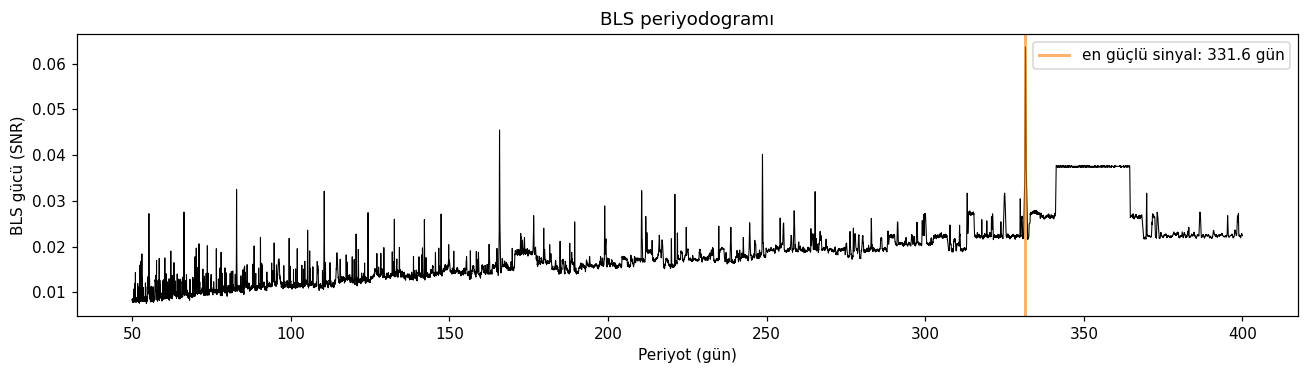

In [4]:
bls = BoxLeastSquares(t, f)
periyotlar = np.exp(np.linspace(np.log(50), np.log(400), 20000))
sureler = [0.25, 0.4, 0.55, 0.7]  # gün
bls_sonuc = bls.power(periyotlar, sureler, objective="snr")

en_iyi = np.argmax(bls_sonuc.power)
P = bls_sonuc.period[en_iyi]
t0 = bls_sonuc.transit_time[en_iyi]
sure = bls_sonuc.duration[en_iyi]
derinlik = bls_sonuc.depth[en_iyi]

print(f"Bulunan periyot : {P:.2f} gün")
print(f"Transit süresi  : {sure * 24:.1f} saat")
print(f"Derinlik        : %{derinlik * 100:.3f}")

plt.figure(figsize=(12, 3.5))
plt.plot(bls_sonuc.period, bls_sonuc.power, color="k", lw=0.7)
plt.axvline(P, color="tab:orange", lw=2, alpha=0.6, label=f"en güçlü sinyal: {P:.1f} gün")
plt.xlabel("Periyot (gün)")
plt.ylabel("BLS gücü (SNR)")
plt.title("BLS periyodogramı")
plt.legend()
plt.tight_layout()
kaydet("3_bls")
plt.show()

### 1.3 Katlama ve iki görünüm
Eğriyi bulunan periyoda göre katlayıp bütün transitleri üst üste koyuyorum. Sonra ağa vereceğim iki girdiyi
eğitim verisiyle aynı şekilde hazırlıyorum (Shallue ve Vanderburg'ün kullandığı ayarlar):

- **Genel görünüm:** Periyodun tamamı, 2001 noktaya bölünmüş hali.
- **Yerel görünüm:** Transitin ±4 süre çevresi, 201 nokta.

Her kutudaki noktaların medyanını alıyorum, sonra görünümü normalize ediyorum (ortanca 0, en derin nokta -1).

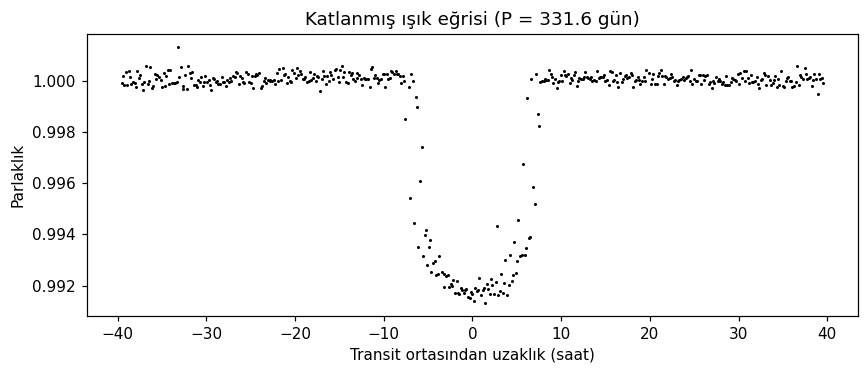

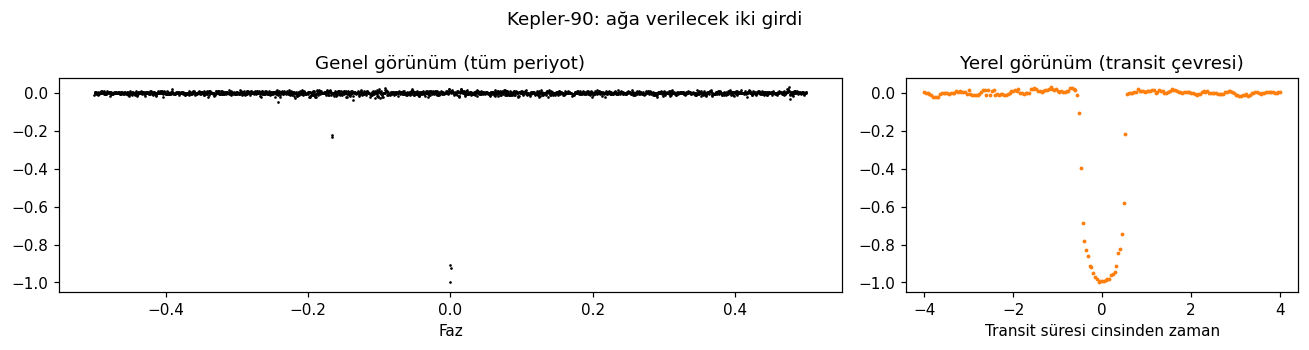

In [5]:
def binle(x, y, bas, son, n, genislik):
    # x ekseninde n eşit aralıklı merkez; her merkezin ±genislik/2 çevresindeki noktaların medyanı
    sira = np.argsort(x)
    x, y = x[sira], y[sira]
    merkezler = np.linspace(bas, son, n)
    sol = np.searchsorted(x, merkezler - genislik / 2)
    sag = np.searchsorted(x, merkezler + genislik / 2)
    sonuc = np.full(n, np.median(y))   # boş kutular genel ortancayla dolduruluyor
    for i in range(n):
        if sag[i] > sol[i]:
            sonuc[i] = np.median(y[sol[i]:sag[i]])
    return sonuc


def normalize(v):
    v = v - np.median(v)
    en_derin = np.abs(v.min())
    return v / en_derin if en_derin > 0 else v


def gorunumler(t, f, P, t0, sure):
    faz = (t - t0 + 0.5 * P) % P - 0.5 * P  # gün cinsinden, transit 0'da
    genel = binle(faz, f, -P / 2, P / 2, GENEL_BIN, P / GENEL_BIN)
    yaricap = min(P / 2, YEREL_SURE * sure)
    yerel = binle(faz, f, -yaricap, yaricap, YEREL_BIN, 0.16 * sure)
    return normalize(genel), normalize(yerel)


def gorunum_ciz(genel, yerel, baslik, dosya=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1]})
    ax[0].plot(np.linspace(-0.5, 0.5, len(genel)), genel, ".", color="k", ms=1.5)
    ax[0].set_title("Genel görünüm (tüm periyot)")
    ax[0].set_xlabel("Faz")
    ax[1].plot(np.linspace(-YEREL_SURE, YEREL_SURE, len(yerel)), yerel, ".", color="tab:orange", ms=3)
    ax[1].set_title("Yerel görünüm (transit çevresi)")
    ax[1].set_xlabel("Transit süresi cinsinden zaman")
    fig.suptitle(baslik)
    plt.tight_layout()
    if dosya:
        kaydet(dosya)
    plt.show()


faz_gun = (t - t0 + 0.5 * P) % P - 0.5 * P
plt.figure(figsize=(8, 3.5))
yakin = np.abs(faz_gun) < 3 * sure
plt.plot(faz_gun[yakin] * 24, f[yakin], ".", ms=2, color="k")
plt.xlabel("Transit ortasından uzaklık (saat)")
plt.ylabel("Parlaklık")
plt.title(f"Katlanmış ışık eğrisi (P = {P:.1f} gün)")
plt.tight_layout()
kaydet("4_katlanmis")
plt.show()

kepler_genel, kepler_yerel = gorunumler(t, f, P, t0, sure)
gorunum_ciz(kepler_genel, kepler_yerel, "Kepler-90: ağa verilecek iki girdi", "5_kepler90_gorunumler")

## 2. Gerçek eğitim verisi: Kepler'in etiketli sinyalleri

Kepler'in ham ışık eğrilerinin tamamı yaklaşık 3 TB, sadece etiketli sinyallerin yıldızları bile yaklaşık 90 GB.
Shallue ve Vanderburg (2018) bu sinyallerin işlenmiş halini (genel görünüm + yerel görünüm + etiket) TFRecord dosyaları olarak paylaşmış.
Dosyalar yaklaşık 145 MB ve zaten eğitim / doğrulama / test olarak bölünmüş halde geliyor.

Etiketler Kepler ekibinin DR24 kataloğundaki incelemelerinden geliyor:

| Etiket | Anlamı | Bizim için |
| --- | --- | --- |
| PC | Gezegen adayı (planet candidate) | 1 |
| AFP | Astrofiziksel sahte pozitif (ör. örten çift yıldız) | 0 |
| NTP | Transit olmayan olay (gürültü, cihaz hatası) | 0 |

UNK (bilinmeyen) etiketli sinyaller bu dosyalarda zaten yok.
`kepler_veri/tfrecord` klasöründe dosyalar yoksa `gdown` ile Google Drive'dan indiriliyor.

In [6]:
TFRECORD_KLASORU = os.path.join(VERI_KLASORU, "tfrecord")
DRIVE_KLASORU = "https://drive.google.com/drive/folders/1Gw-o7sgWC1Y_mlaehN85qH5XC161EHSE"


def dosyalari_bul():
    return {b: sorted(glob.glob(os.path.join(TFRECORD_KLASORU, f"{b}-*"))) for b in ["train", "val", "test"]}


dosyalar = dosyalari_bul()
if not all(dosyalar.values()):
    import gdown
    print("Veri bulunamadı, Google Drive'dan indiriliyor (yaklaşık 145 MB)...")
    gdown.download_folder(DRIVE_KLASORU, output=TFRECORD_KLASORU, quiet=True)
    dosyalar = dosyalari_bul()

print({k: len(v) for k, v in dosyalar.items()}, "dosya")


def ozellik(ornek, ad):
    # Bir TFRecord örneğinden, türüne bakmadan, bir özelliğin değerlerini alıyor
    f = ornek.features.feature[ad]
    for tur in ("float_list", "int64_list", "bytes_list"):
        deger = getattr(f, tur).value
        if len(deger):
            return list(deger)
    return []


def tfrecord_oku(dosya_listesi):
    genel, yerel, etiketler, kepid, gezegen_no, periyot = [], [], [], [], [], []
    for kayit in tf.data.TFRecordDataset(dosya_listesi):
        ornek = tf.train.Example.FromString(kayit.numpy())
        etiket = ozellik(ornek, "av_training_set")[0].decode()
        if etiket not in ("PC", "AFP", "NTP"):
            continue
        genel.append(ozellik(ornek, "global_view"))
        yerel.append(ozellik(ornek, "local_view"))
        etiketler.append(etiket)
        kepid.append(int(ozellik(ornek, "kepid")[0]))
        gezegen_no.append(int(ozellik(ornek, "tce_plnt_num")[0]))
        periyot.append(float(ozellik(ornek, "tce_period")[0]))
    etiketler = np.array(etiketler)
    return {
        "genel": np.array(genel, dtype="float32")[..., None],
        "yerel": np.array(yerel, dtype="float32")[..., None],
        "etiket_adi": etiketler,
        "y": (etiketler == "PC").astype("float32"),
        "kepid": np.array(kepid),
        "gezegen_no": np.array(gezegen_no),
        "periyot": np.array(periyot),
    }


veri = {b: tfrecord_oku(dosyalar[b]) for b in ["train", "val", "test"]}

for bolum, ad in [("train", "Eğitim"), ("val", "Doğrulama"), ("test", "Test")]:
    adlar = veri[bolum]["etiket_adi"]
    print(f"{ad:10s}: {len(adlar):6d} sinyal | PC: {np.sum(adlar == 'PC'):5d} | "
          f"AFP: {np.sum(adlar == 'AFP'):5d} | NTP: {np.sum(adlar == 'NTP'):5d}")

{'train': 8, 'val': 1, 'test': 1} dosya


Eğitim    :  12589 sinyal | PC:  2885 | AFP:  7643 | NTP:  2061
Doğrulama :   1574 sinyal | PC:   355 | AFP:   983 | NTP:   236
Test      :   1574 sinyal | PC:   360 | AFP:   970 | NTP:   244


Her etiketten birer örneğe bakalım. Gezegen adayında düz tabanlı bir düşüş, örten çiftte genelde daha V şeklinde
bir düşüş ya da genel görünümde ikinci bir düşüş, NTP'de ise belirgin bir şekli olmayan gürültü görmeyi bekliyoruz.

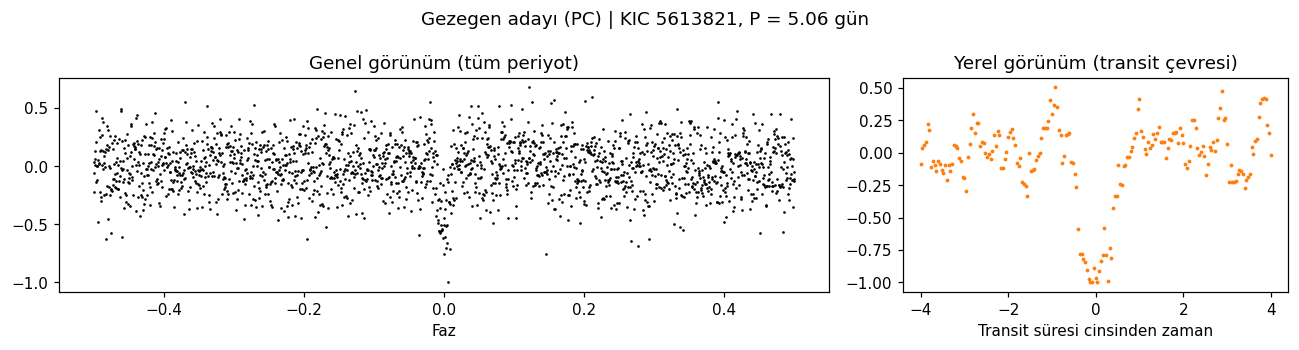

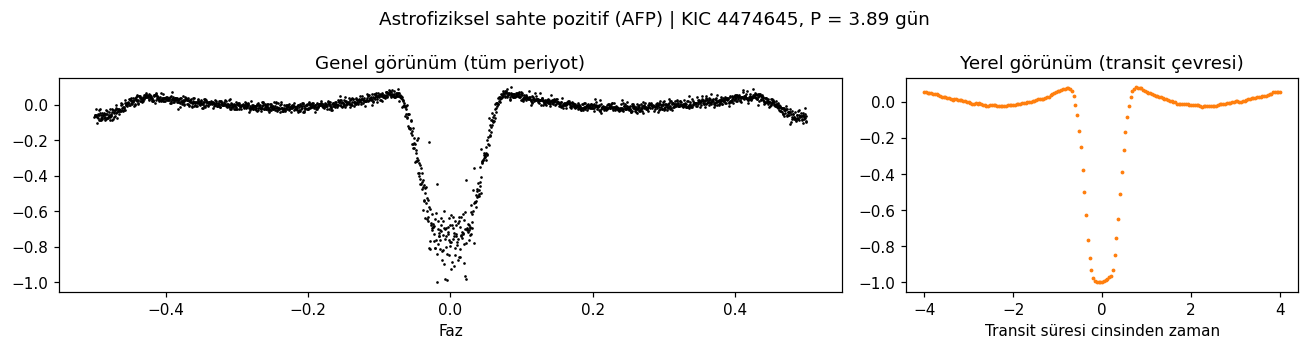

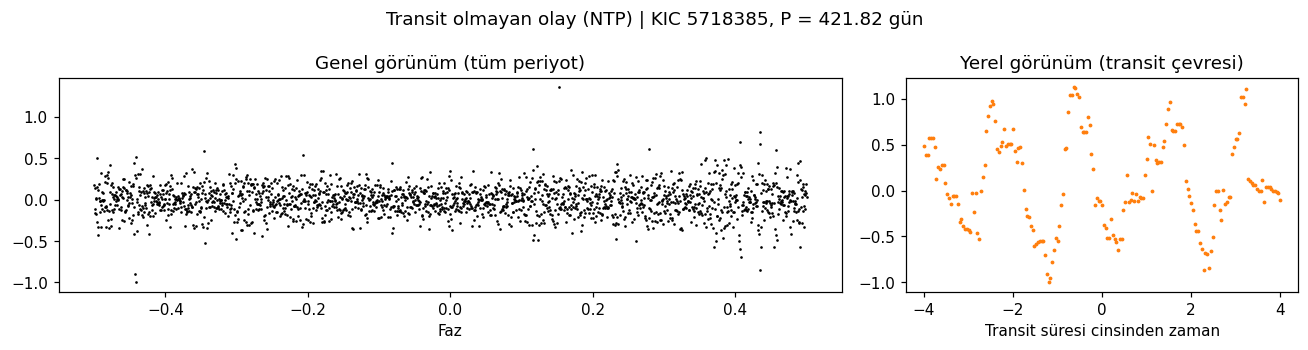

In [7]:
ornekler = [("PC", "Gezegen adayı (PC)", "6_ornek_pc"),
            ("AFP", "Astrofiziksel sahte pozitif (AFP)", "6_ornek_afp"),
            ("NTP", "Transit olmayan olay (NTP)", "6_ornek_ntp")]
rng = np.random.default_rng(7)
for etiket, ad, dosya in ornekler:
    i = rng.choice(np.flatnonzero(veri["train"]["etiket_adi"] == etiket))
    gorunum_ciz(veri["train"]["genel"][i, :, 0], veri["train"]["yerel"][i, :, 0],
                f"{ad} | KIC {veri['train']['kepid'][i]}, P = {veri['train']['periyot'][i]:.2f} gün", dosya)

## 3. Ağın mimarisi: 1D CNN

Genel ve yerel görünüm ayrı evrişim kolonlarından geçiyor. Evrişim katmanları düşüşün şeklini öğreniyor,
havuzlama katmanları veriyi özetliyor. Sonra iki kolon birleşiyor, tam bağlantılı katmanlardan geçip
sigmoid ile 0-1 arasında bir gezegen olasılığına dönüşüyor. Yapı, Shallue ve Vanderburg'ün ağının biraz küçültülmüş hali
(onlarda genel kolonda 5 blok ve 4 tane 512'lik tam bağlantılı katman var).

In [8]:
def evrisim_kolonu(girdi, filtreler, havuz):
    x = girdi
    for adet in filtreler:
        x = layers.Conv1D(adet, 5, padding="same", activation="relu")(x)
        x = layers.Conv1D(adet, 5, padding="same", activation="relu")(x)
        x = layers.MaxPooling1D(pool_size=havuz, strides=2)(x)
    return layers.Flatten()(x)


def model_kur():
    genel_girdi = keras.Input(shape=(GENEL_BIN, 1), name="genel_gorunum")
    yerel_girdi = keras.Input(shape=(YEREL_BIN, 1), name="yerel_gorunum")

    genel_kolon = evrisim_kolonu(genel_girdi, [16, 32, 64, 128], havuz=5)
    yerel_kolon = evrisim_kolonu(yerel_girdi, [16, 32], havuz=7)

    x = layers.concatenate([genel_kolon, yerel_kolon])
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    cikti = layers.Dense(1, activation="sigmoid", name="gezegen_olasiligi")(x)

    m = keras.Model([genel_girdi, yerel_girdi], cikti)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m


model = model_kur()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ genel_gorunum       │ (None, 2001, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 2001, 16)  │         96 │ genel_gorunum[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 2001, 16)  │      1,296 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 999, 16)   │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 999, 32)   │      2,592 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 999, 32)   │      5,152 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 498, 32)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ yerel_gorunum       │ (None, 201, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 498, 64)   │     10,304 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 201, 16)   │         96 │ yerel_gorunum[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 498, 64)   │     20,544 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 201, 16)   │      1,296 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 247, 64)   │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 98, 16)    │          0 │ conv1d_9[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 247, 128)  │     41,088 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 98, 32)    │      2,592 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 247, 128)  │     82,048 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 98, 32)    │      5,152 │ conv1d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 122, 128)  │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 46, 32)    │          0 │ conv1d_11[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 15616)     │          0 │ max_pooling1d_3[

 Total params: 4,580,065 (17.47 MB)

 Trainable params: 4,580,065 (17.47 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Eğitim
Kayıp fonksiyonu ikili çapraz entropi, optimizasyon Adam. Eğitim setinde gezegen adayları yaklaşık %23 ile azınlıkta,
bu yüzden `class_weight` ile gezegen örneklerine daha fazla ağırlık veriyorum (sınıf dengesizliği).
Ayrıca her turda örneklerin yarısını zaman ekseninde ters çeviriyorum: bir transit ters çevrilince de transit olduğu için
bu ağa bedava yeni örnek demek (Shallue ve Vanderburg da bunu yapmış).
Doğrulama kaybı 5 tur boyunca iyileşmezse eğitimi durduruyorum (erken durdurma).

In [9]:
MODEL_DOSYA = os.path.join(SONUC_KLASORU, "model.keras")


def girdiler(b):
    return [veri[b]["genel"], veri[b]["yerel"]]


y_egitim = veri["train"]["y"]
oran = (1 - y_egitim.mean()) / y_egitim.mean()
sinif_agirligi = {0: 1.0, 1: float(oran)}
print(f"Eğitimde gezegen oranı: %{y_egitim.mean() * 100:.1f} -> gezegen ağırlığı {oran:.2f}")


def egitim_akisi(batch=64):
    g, l, y = veri["train"]["genel"], veri["train"]["yerel"], y_egitim
    w = np.where(y == 1, oran, 1.0).astype("float32")

    def cevir(gg, ll, yy, ww):
        ters = tf.random.uniform([]) < 0.5
        gg = tf.cond(ters, lambda: tf.reverse(gg, [0]), lambda: gg)
        ll = tf.cond(ters, lambda: tf.reverse(ll, [0]), lambda: ll)
        return (gg, ll), yy, ww

    ds = tf.data.Dataset.from_tensor_slices((g, l, y, w)).shuffle(len(y), seed=42)
    return ds.map(cevir).batch(batch).prefetch(tf.data.AUTOTUNE)


if not YENIDEN_EGIT and os.path.exists(MODEL_DOSYA):
    model = keras.models.load_model(MODEL_DOSYA)
    gecmis = None
    print("Kayıtlı model yüklendi:", MODEL_DOSYA)
else:
    erken_durdurma = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    gecmis = model.fit(egitim_akisi(),
                       validation_data=(tuple(girdiler("val")), veri["val"]["y"]),
                       epochs=50, callbacks=[erken_durdurma], verbose=2)
    model.save(MODEL_DOSYA)
    print("Model kaydedildi:", MODEL_DOSYA)

if gecmis is not None:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(gecmis.history["loss"], label="eğitim")
    ax[0].plot(gecmis.history["val_loss"], label="doğrulama")
    ax[0].set_title("Kayıp (ikili çapraz entropi)")
    ax[0].set_xlabel("Tur (epoch)")
    ax[0].legend()
    ax[1].plot(gecmis.history["auc"], label="eğitim")
    ax[1].plot(gecmis.history["val_auc"], label="doğrulama")
    ax[1].set_title("AUC")
    ax[1].set_xlabel("Tur (epoch)")
    ax[1].legend()
    plt.tight_layout()
    kaydet("7_egitim_egrileri")
    plt.show()

Eğitimde gezegen oranı: %22.9 -> gezegen ağırlığı 3.36
Kayıtlı model yüklendi: sonuclar\model.keras


## 5. Değerlendirme
Modeli hiç görmediği test setinde ölçüyorum. Sadece doğruluğa değil, kesinlik, duyarlılık, F1 ve ROC eğrisine de bakıyorum.
Karşılaştırma için: Shallue ve Vanderburg'ün tam boyutlu ağı aynı test setinde %96 doğruluk ve 0,988 AUC almış.

Test sinyali  : 1574 (gezegen adayı: 360)
Doğruluk      : 0.959   (hepsine 'gezegen değil' deseydik: 0.771)
Kesinlik      : 0.866
Duyarlılık    : 0.972
F1 skoru      : 0.916
ROC AUC       : 0.988


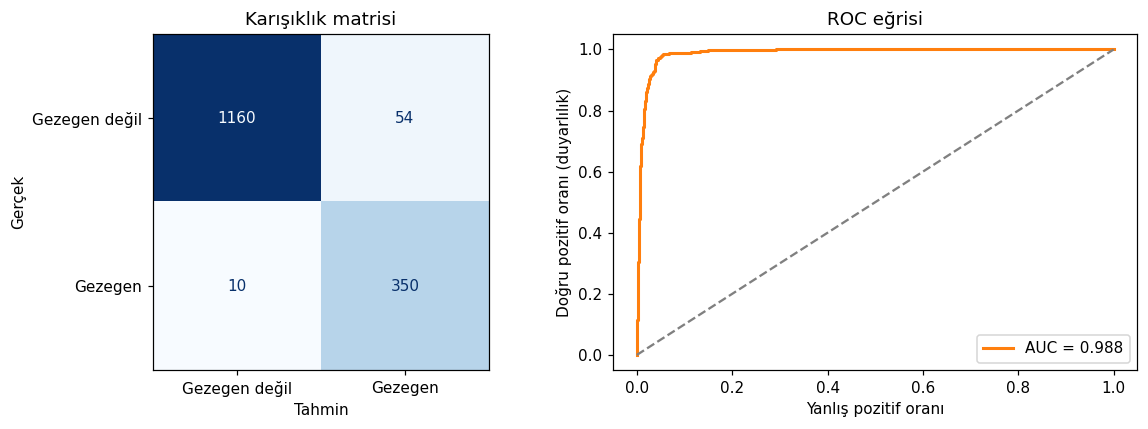

In [10]:
olasilik_test = model.predict(girdiler("test"), verbose=0).ravel()
y_test = veri["test"]["y"]
tahmin_test = (olasilik_test >= 0.5).astype(int)

dogruluk = np.mean(tahmin_test == y_test)
kesinlik = precision_score(y_test, tahmin_test)
duyarlilik = recall_score(y_test, tahmin_test)
f1 = f1_score(y_test, tahmin_test)
auc = roc_auc_score(y_test, olasilik_test)
herkes_hayir = 1 - y_test.mean()

print(f"Test sinyali  : {len(y_test)} (gezegen adayı: {int(y_test.sum())})")
print(f"Doğruluk      : {dogruluk:.3f}   (hepsine 'gezegen değil' deseydik: {herkes_hayir:.3f})")
print(f"Kesinlik      : {kesinlik:.3f}")
print(f"Duyarlılık    : {duyarlilik:.3f}")
print(f"F1 skoru      : {f1:.3f}")
print(f"ROC AUC       : {auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, tahmin_test),
                       display_labels=["Gezegen değil", "Gezegen"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Karışıklık matrisi")
ax[0].set_xlabel("Tahmin")
ax[0].set_ylabel("Gerçek")
fpr, tpr, _ = roc_curve(y_test, olasilik_test)
ax[1].plot(fpr, tpr, color="tab:orange", lw=2, label=f"AUC = {auc:.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("Yanlış pozitif oranı")
ax[1].set_ylabel("Doğru pozitif oranı (duyarlılık)")
ax[1].set_title("ROC eğrisi")
ax[1].legend()
plt.tight_layout()
kaydet("8_test_sonuclari")
plt.show()

Hangi türde zorlanıyor? Test setini etiketlere göre ayırıp bakalım:

In [11]:
etiket_test = veri["test"]["etiket_adi"]
for etiket, ad in [("PC", "Gezegen adayı (PC)"), ("AFP", "Sahte pozitif (AFP)"), ("NTP", "Transit olmayan (NTP)")]:
    secili = etiket_test == etiket
    dogru = np.mean(tahmin_test[secili] == y_test[secili])
    print(f"{ad:24s}: %{dogru * 100:.1f} doğru ({secili.sum()} sinyal)")

Gezegen adayı (PC)      : %97.2 doğru (360 sinyal)
Sahte pozitif (AFP)     : %94.7 doğru (970 sinyal)
Transit olmayan (NTP)   : %98.8 doğru (244 sinyal)


Ağın en emin olduğu ama yanıldığı iki örneğe bakmak da öğretici:

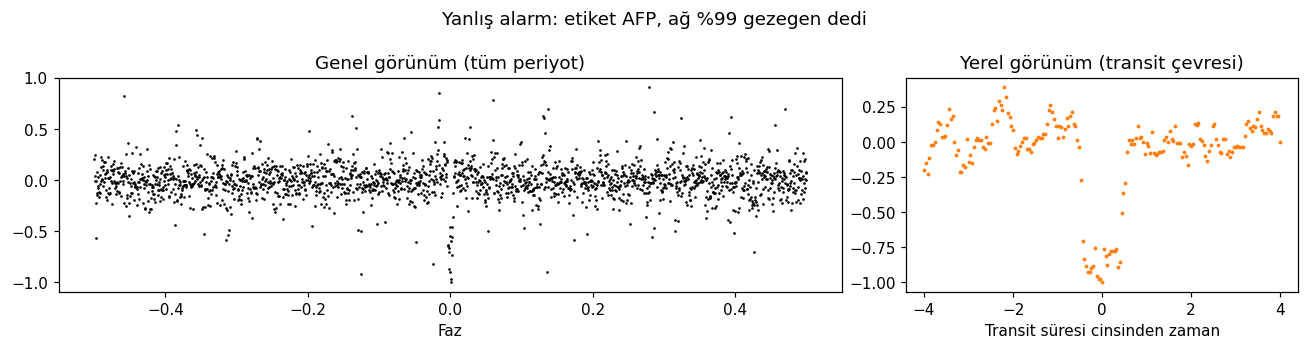

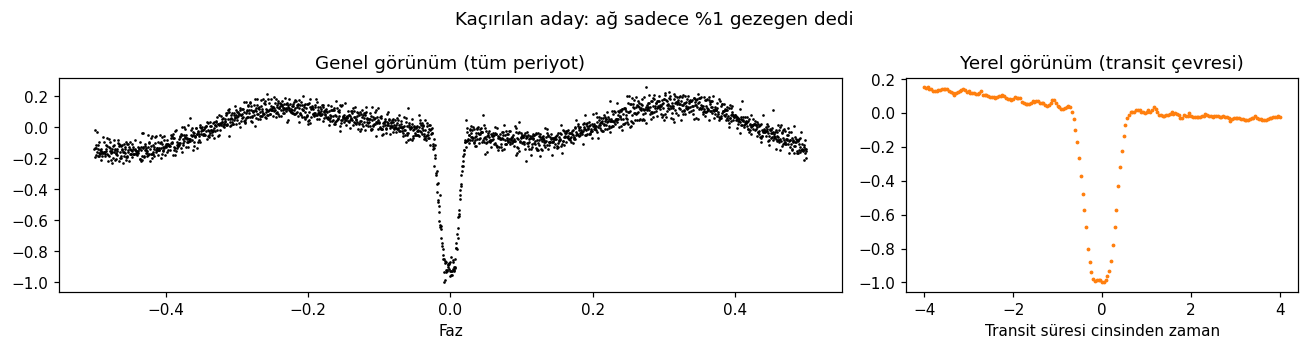

In [12]:
yanlis_poz = np.flatnonzero((tahmin_test == 1) & (y_test == 0))
yanlis_neg = np.flatnonzero((tahmin_test == 0) & (y_test == 1))
T = veri["test"]
if yanlis_poz.size:
    i = yanlis_poz[np.argmax(olasilik_test[yanlis_poz])]
    gorunum_ciz(T["genel"][i, :, 0], T["yerel"][i, :, 0],
                f"Yanlış alarm: etiket {T['etiket_adi'][i]}, ağ %{olasilik_test[i] * 100:.0f} gezegen dedi", "9_yanlis_alarm")
if yanlis_neg.size:
    i = yanlis_neg[np.argmin(olasilik_test[yanlis_neg])]
    gorunum_ciz(T["genel"][i, :, 0], T["yerel"][i, :, 0],
                f"Kaçırılan aday: ağ sadece %{olasilik_test[i] * 100:.0f} gezegen dedi", "9_kacirilan")

## 6. Kepler-90

**6.1 Veri setindeki Kepler-90 sinyali.** Kepler-90'ın (KIC 11442793) DR24 kataloğundaki sinyali eğitim setinde var.
Ağ bu örneği eğitimde gördüğü için bu sadece bir kontrol, gerçek bir test değil.

In [13]:
KEPLER90 = 11442793
for bolum, ad in [("train", "eğitim"), ("val", "doğrulama"), ("test", "test")]:
    secili = np.flatnonzero(veri[bolum]["kepid"] == KEPLER90)
    if secili.size == 0:
        continue
    p = model.predict([veri[bolum]["genel"][secili], veri[bolum]["yerel"][secili]], verbose=0).ravel()
    for i, olas in zip(secili, p):
        print(f"Kepler-90 sinyal {veri[bolum]['gezegen_no'][i]} ({ad} setinde) | P = {veri[bolum]['periyot'][i]:.1f} gün | "
              f"etiket: {veri[bolum]['etiket_adi'][i]} | ağın gezegen olasılığı: {olas:.3f}")

Kepler-90 sinyal 1 (eğitim setinde) | P = 331.6 gün | etiket: PC | ağın gezegen olasılığı: 0.976


**6.2 Kendi hazırladığım Kepler-90 görünümü.** Şimdi en başta kendim indirip işlediğim Kepler-90 ışık eğrisini ağa veriyorum.
Karşılaştırma için aynı veriyi **yanlış bir periyotla** katlayıp tekrar soruyorum. Yanlış periyotta transitler üst üste gelmediği için
ağın "gezegen değil" demesini bekliyorum.

Kepler-90, BLS periyodu (331.6 gün) ile: gezegen olasılığı = 0.986
Kepler-90, yanlış periyot (244.4 gün) ile: gezegen olasılığı = 0.001


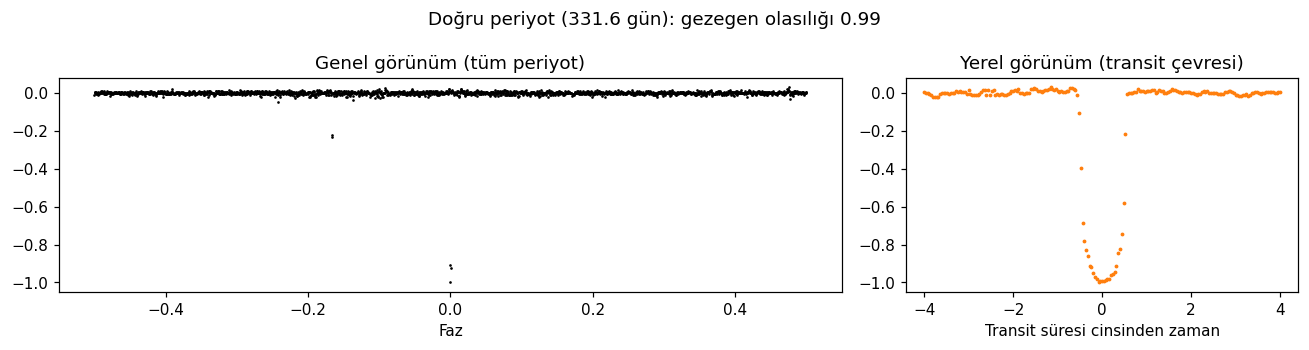

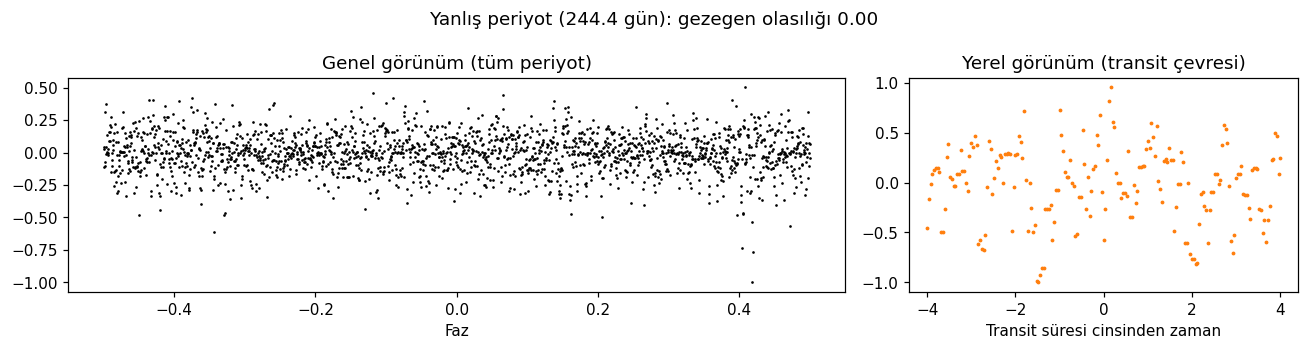

In [14]:
def tahmin_et(genel, yerel):
    g = genel.reshape(1, GENEL_BIN, 1).astype("float32")
    y = yerel.reshape(1, YEREL_BIN, 1).astype("float32")
    return float(model.predict([g, y], verbose=0)[0, 0])


p_dogru = tahmin_et(kepler_genel, kepler_yerel)
print(f"Kepler-90, BLS periyodu ({P:.1f} gün) ile: gezegen olasılığı = {p_dogru:.3f}")

P_yanlis = P * 0.737
yanlis_genel, yanlis_yerel = gorunumler(t, f, P_yanlis, t0 + 17.3, sure)
p_yanlis = tahmin_et(yanlis_genel, yanlis_yerel)
print(f"Kepler-90, yanlış periyot ({P_yanlis:.1f} gün) ile: gezegen olasılığı = {p_yanlis:.3f}")

gorunum_ciz(kepler_genel, kepler_yerel, f"Doğru periyot ({P:.1f} gün): gezegen olasılığı {p_dogru:.2f}", "10_kepler90_dogru")
gorunum_ciz(yanlis_genel, yanlis_yerel, f"Yanlış periyot ({P_yanlis:.1f} gün): gezegen olasılığı {p_yanlis:.2f}", "10_kepler90_yanlis")

## 7. Ağın içine bakış: ağırlıklar ne öğrendi?

Bir 1D evrişim katmanındaki her filtre sadece **5 sayıdan (ağırlık) ve 1 sabitten (bias)** oluşuyor.
Filtre ışık eğrisinin üzerinde kayıyor ve her noktada şu hesabı yapıyor:

$$y[t] = \mathrm{ReLU}\Big(b + \sum_{k=0}^{4} w_k \cdot x[t + k - 2]\Big)$$

Yani filtre, eğrinin 5 noktalık bir parçasıyla kendi ağırlıklarını çarpıp topluyor. Parça filtrenin "aradığı" şekle
benziyorsa sonuç büyük çıkıyor, benzemiyorsa küçük ya da sıfır (ReLU negatifleri sıfırlıyor).
Eğitimde ağırlıklar rastgele başlıyor; geri yayılım her turda bunları kaybı azaltacak yönde biraz değiştiriyor.

### 7.1 Katman katman ağırlık sayıları

In [15]:
toplam = 0
print(f"{'Katman':26s} {'Ağırlık şekli':22s} {'Parametre':>10s}")
for katman in model.layers:
    agirliklar = katman.get_weights()
    if not agirliklar:
        continue
    adet = sum(a.size for a in agirliklar)
    toplam += adet
    sekil = " + ".join(str(tuple(a.shape)) for a in agirliklar)
    print(f"{katman.name:26s} {sekil:22s} {adet:>10,}")
print(f"{'TOPLAM':49s} {toplam:>10,}")

Katman                     Ağırlık şekli           Parametre
conv1d                     (5, 1, 16) + (16,)             96
conv1d_1                   (5, 16, 16) + (16,)         1,296
conv1d_2                   (5, 16, 32) + (32,)         2,592
conv1d_3                   (5, 32, 32) + (32,)         5,152
conv1d_4                   (5, 32, 64) + (64,)        10,304
conv1d_8                   (5, 1, 16) + (16,)             96
conv1d_5                   (5, 64, 64) + (64,)        20,544
conv1d_9                   (5, 16, 16) + (16,)         1,296
conv1d_6                   (5, 64, 128) + (128,)      41,088
conv1d_10                  (5, 16, 32) + (32,)         2,592
conv1d_7                   (5, 128, 128) + (128,)     82,048
conv1d_11                  (5, 32, 32) + (32,)         5,152
dense                      (17088, 256) + (256,)   4,374,784
dense_1                    (256, 128) + (128,)        32,896
gezegen_olasiligi          (128, 1) + (1,)               129
TOPLAM                  

### 7.2 Bir filtreyi elle hesaplamak
Yerel kolonun ilk evrişim katmanından, Kepler-90'ın transitine en güçlü tepki veren filtreyi alıyorum.
Önce Keras'ın hesapladığı çıktıyı, sonra aynı şeyi sadece numpy ile, yukarıdaki formülle kendim hesaplıyorum.
İkisi aynı çıkarsa ağırlıkların tam olarak nasıl kullanıldığını göstermiş oluyoruz.

Katman: conv1d_8 | ağırlık şekli: (5, 1, 16) | bias şekli: (16,)
Seçilen filtre: 15 | ağırlıklar: [-0.111 -0.136 -0.252 -0.128 -0.111] | bias: -0.008
Keras çıktısıyla elle hesap aynı mı? True


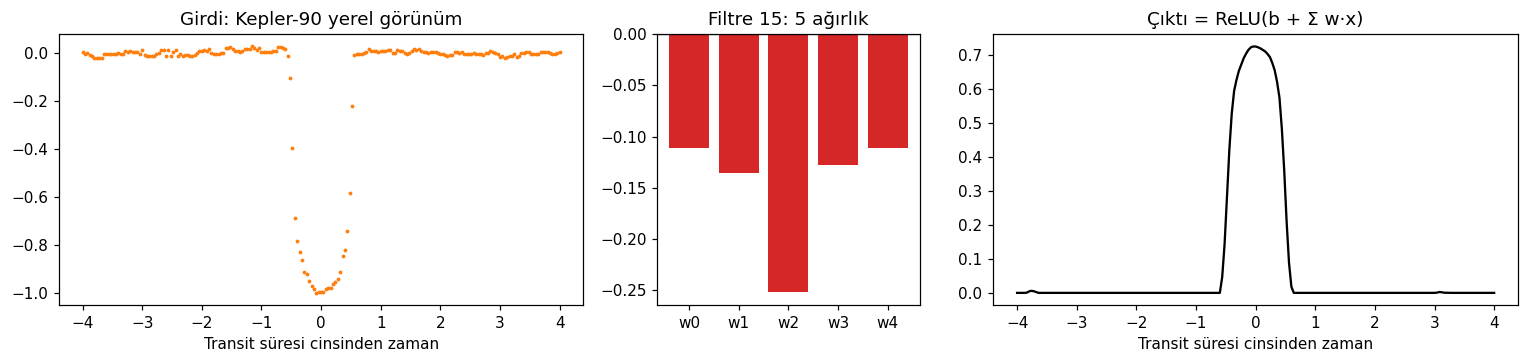

In [16]:
def ilk_evrisim(uzunluk):
    # Girdisi (uzunluk, 1) olan ilk Conv1D katmanını bul
    for katman in model.layers:
        if isinstance(katman, layers.Conv1D) and tuple(katman.input.shape[1:]) == (uzunluk, 1):
            return katman


konv = ilk_evrisim(YEREL_BIN)
W, b = konv.get_weights()            # W: (5, 1, 16)  b: (16,)
print("Katman:", konv.name, "| ağırlık şekli:", W.shape, "| bias şekli:", b.shape)

x = kepler_yerel.astype("float32")
keras_cikti = konv(x.reshape(1, -1, 1)).numpy()[0]   # katmanı doğrudan çağırıyoruz -> (201, 16)

# Transit bölgesinde en güçlü tepki veren filtre
transit = np.abs(np.linspace(-YEREL_SURE, YEREL_SURE, YEREL_BIN)) < 0.6
secilen = int(np.argmax(keras_cikti[transit].max(axis=0)))
w = W[:, 0, secilen]
print(f"Seçilen filtre: {secilen} | ağırlıklar: {np.round(w, 3)} | bias: {b[secilen]:.3f}")

# Aynı hesabı elle yapıyoruz: kenarlara 2'şer sıfır ekle ("same" dolgu), 5'li pencereyle kaydır
x_dolgulu = np.pad(x, 2)
elle = np.array([b[secilen] + np.dot(w, x_dolgulu[t:t + 5]) for t in range(YEREL_BIN)])
elle = np.maximum(elle, 0)   # ReLU
print("Keras çıktısıyla elle hesap aynı mı?", np.allclose(elle, keras_cikti[:, secilen], atol=1e-5))

zaman = np.linspace(-YEREL_SURE, YEREL_SURE, YEREL_BIN)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), gridspec_kw={"width_ratios": [2, 1, 2]})
ax[0].plot(zaman, x, ".", color="tab:orange", ms=3)
ax[0].set_title("Girdi: Kepler-90 yerel görünüm")
ax[0].set_xlabel("Transit süresi cinsinden zaman")
ax[1].bar(range(5), w, color=["tab:red" if v < 0 else "tab:blue" for v in w])
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(range(5), ["w0", "w1", "w2", "w3", "w4"])
ax[1].set_title(f"Filtre {secilen}: 5 ağırlık")
ax[2].plot(zaman, elle, color="k")
ax[2].set_title("Çıktı = ReLU(b + Σ w·x)")
ax[2].set_xlabel("Transit süresi cinsinden zaman")
plt.tight_layout()
kaydet("11_tek_filtre")
plt.show()

### 7.3 İlk katmandaki 16 filtrenin hepsi
Solda her filtrenin 5 ağırlığı (mavi pozitif, kırmızı negatif), sağda Kepler-90'ın yerel görünümüne verdikleri tepki.
Bazı filtreler transitin **giriş kenarında**, bazıları **çıkış kenarında**, bazıları da **tabanında** yanıyor.
Bir sonraki katman bu basit parçaları birleştirip "düz tabanlı U şekli" gibi daha karmaşık kalıpları tanıyor.

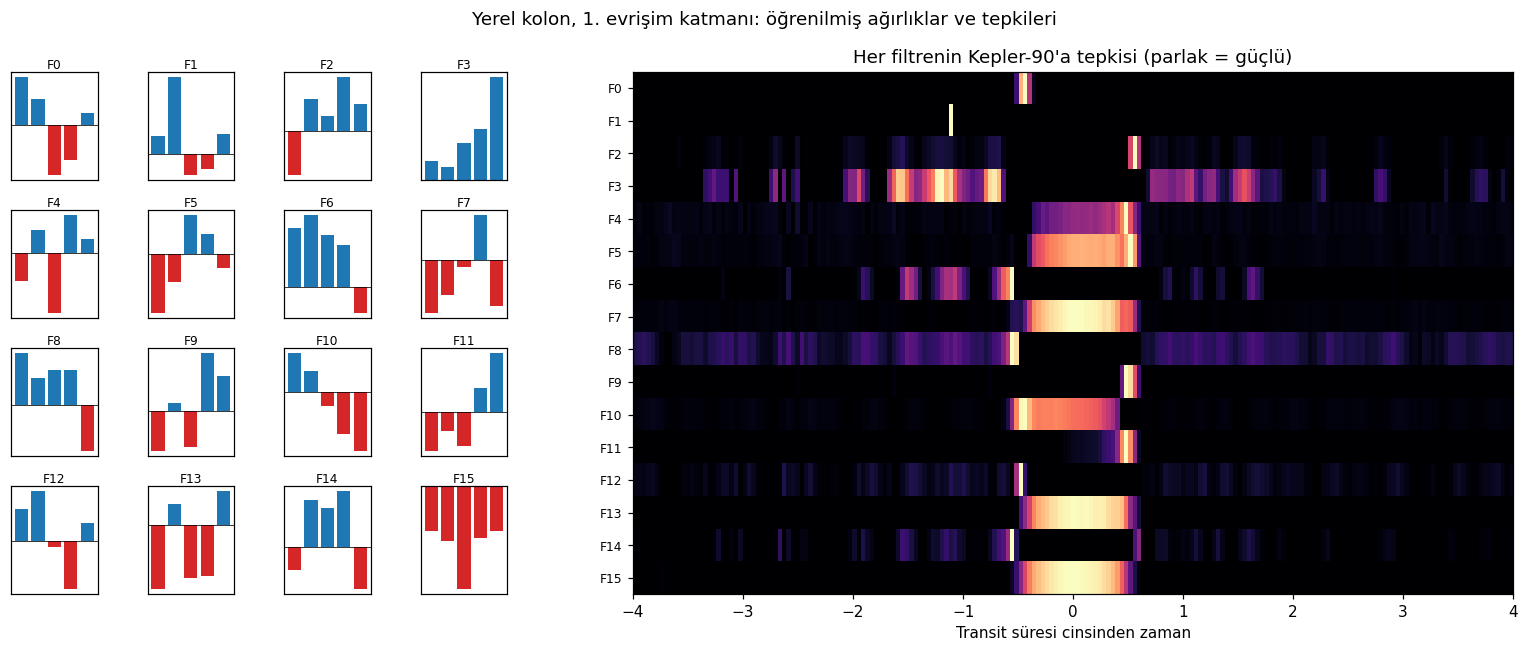

In [17]:
fig = plt.figure(figsize=(14, 6))
izgara = fig.add_gridspec(4, 8, width_ratios=[1, 1, 1, 1, 0.3, 3, 3, 3])
for i in range(16):
    a = fig.add_subplot(izgara[i // 4, i % 4])
    wi = W[:, 0, i]
    a.bar(range(5), wi, color=["tab:red" if v < 0 else "tab:blue" for v in wi])
    a.axhline(0, color="k", lw=0.5)
    a.set_xticks([])
    a.set_yticks([])
    a.set_title(f"F{i}", fontsize=8, pad=2)
isi = fig.add_subplot(izgara[:, 5:])
cikti_norm = keras_cikti / (keras_cikti.max(axis=0, keepdims=True) + 1e-9)
isi.imshow(cikti_norm.T, aspect="auto", cmap="magma", extent=[-YEREL_SURE, YEREL_SURE, 15.5, -0.5])
isi.set_yticks(range(16), [f"F{i}" for i in range(16)], fontsize=8)
isi.set_xlabel("Transit süresi cinsinden zaman")
isi.set_title("Her filtrenin Kepler-90'a tepkisi (parlak = güçlü)")
fig.suptitle("Yerel kolon, 1. evrişim katmanı: öğrenilmiş ağırlıklar ve tepkileri")
plt.tight_layout()
kaydet("12_filtreler")
plt.show()

### 7.4 Ağ eğrinin neresine bakıyor?
Yerel görünümün küçük bir parçasını sırayla "siliyorum" (o noktaları 0 yapıyorum, yani düz çizgi) ve ağın gezegen olasılığının
ne kadar düştüğüne bakıyorum. Olasılık hangi parça silinince çok düşüyorsa, ağ kararını o bölgeye bakarak veriyor demektir.

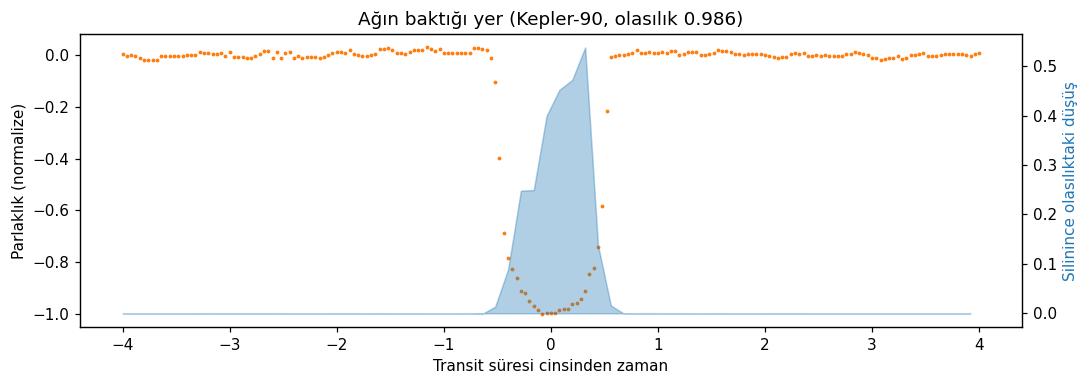

En kritik bölge: transit ortasından +0.32 süre uzakta, silinince olasılık 0.986 -> 0.447


In [18]:
def onem_haritasi(genel, yerel, pencere=9):
    temel = tahmin_et(genel, yerel)
    girdiler_y = []
    for bas in range(0, YEREL_BIN, 3):
        y = yerel.copy()
        y[max(0, bas - pencere // 2): bas + pencere // 2 + 1] = 0
        girdiler_y.append(y)
    g = np.repeat(genel.reshape(1, -1, 1), len(girdiler_y), axis=0).astype("float32")
    y = np.array(girdiler_y, dtype="float32")[..., None]
    p = model.predict([g, y], verbose=0).ravel()
    merkezler = np.arange(0, YEREL_BIN, 3)
    return temel, merkezler, temel - p


temel, merkez, dusus = onem_haritasi(kepler_genel, kepler_yerel)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(zaman, kepler_yerel, ".", color="tab:orange", ms=3, label="yerel görünüm")
ax2 = ax.twinx()
ax2.fill_between(zaman[merkez], 0, dusus, color="tab:blue", alpha=0.35, label="olasılık düşüşü")
ax2.set_ylabel("Silinince olasılıktaki düşüş", color="tab:blue")
ax.set_xlabel("Transit süresi cinsinden zaman")
ax.set_ylabel("Parlaklık (normalize)")
ax.set_title(f"Ağın baktığı yer (Kepler-90, olasılık {temel:.3f})")
plt.tight_layout()
kaydet("13_onem_haritasi")
plt.show()
print(f"En kritik bölge: transit ortasından {zaman[merkez][np.argmax(dusus)]:+.2f} süre uzakta, "
      f"silinince olasılık {temel:.3f} -> {temel - dusus.max():.3f}")

## Özet

- Kepler-90'ın gerçek ışık eğrisinde trend temizleme, BLS ve katlama ile büyük gezegenlerinden birinin transitini buldum.
- Genel ve yerel görünümü kullanan 1D CNN'i Kepler ekibinin etiketlediği gerçek sinyallerle eğittim ve hiç görmediği test setinde değerlendirdim.
- Doğru periyotla katlanan Kepler-90 verisine ağın verdiği olasılığı, yanlış periyotla katlanmış haliyle karşılaştırdım.

Kaynak: Shallue, C. J. ve Vanderburg, A. (2018), *Identifying Exoplanets with Deep Learning: A Five-planet Resonant Chain around Kepler-80 and an Eighth Planet around Kepler-90*, The Astronomical Journal 155, 94.